## Statistical Significance
- Evaluating the classifier models across different thresholds
- Testing on Binary and Multi-Class Classification
- Testing each model's statistical significance using p-values and McNemar's Test

In [28]:
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler

from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parents[0]))
from src.tuning import show_metrics, visualize_metrics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# load the data
df = pd.read_csv('../data/processed/sms_cleaned_data.csv')
df = df[(df['target'] == 0) | (df['target'] == 1)]
df

,date,text,carrier,target,punctuation_count,text_count,has_url,has_money_mention,has_phone_in_text,exclamation_count,uppercase_ratio,word_count,year,month
2,2026-03-27 06:23:44.260,papalduhin kita moneytoken ngayon basta bahala...,Smart,1,6,167,0.0,1.0,0.0,0.0,0.071856,22,2026,March
3,2026-02-17 10:25:35.838,boss panalunin kita pinata win moneytoken haba...,Smart,1,11,186,0.0,1.0,0.0,0.0,0.016129,20,2026,February
5,2025-11-15 10:25:41.961,okay makipag deal sayo cash ipapanalo kita mon...,Smart,1,10,195,0.0,1.0,0.0,0.0,0.020513,25,2025,November
7,2025-08-27 09:28:23.142,fex parcel p iisddcddtba reach please contact ...,Smart,1,5,109,0.0,0.0,1.0,0.0,0.119266,10,2025,August
8,2025-08-19 08:57:21.957,smart reminds reward points expire today pleas...,Unknown,1,11,114,1.0,0.0,0.0,0.0,0.043860,11,2025,August
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999,2018-11-09 01:33:50.801,properties bgc makati moa san juan binondo pas...,Smart,0,9,195,0.0,0.0,0.0,1.0,0.220513,20,2018,November
1010,2018-05-06 04:37:35.505,available instantly ageless effective proven e...,Smart,0,7,148,0.0,0.0,0.0,0.0,0.162162,15,2018,May
1013,2018-04-19 11:11:20.770,co makati needs software java developer bachel...,Globe,0,8,171,1.0,0.0,0.0,0.0,0.058480,17,2018,April
1014,2018-03-22 10:45:57.147,co makati needs software java developer bachel...,Smart,0,9,187,1.0,0.0,0.0,0.0,0.053476,19,2018,March


## Tuned CNB and MNB Models

In [29]:
df['dedup_group_id'] = pd.factorize(df['text'])[0]

binary_cols = ['has_url', 'has_money_mention', 'has_phone_in_text']
numericals = ['exclamation_count', 'text_count', 'word_count',
              'punctuation_count', 'uppercase_ratio']

x = df['text']
y = df['target']

# splitting and vectorization
vectorizer = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.8, sublinear_tf=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scaler = MinMaxScaler(clip=True)
train_idx, test_idx = next(sgkf.split(x, y, groups=df['dedup_group_id']))

train_data = df.iloc[train_idx].reset_index(drop=True)
test_data = df.iloc[test_idx].reset_index(drop=True)

X_train = vectorizer.fit_transform(train_data['text'])
X_test = vectorizer.transform(test_data['text'])
y_train = train_data['target']
y_test = test_data['target']

num_train = scaler.fit_transform(train_data[numericals])
num_test  = scaler.transform(test_data[numericals])

bin_train = train_data[binary_cols].to_numpy(dtype=float)
bin_test  = test_data[binary_cols].to_numpy(dtype=float)

X_train = hstack([X_train, csr_matrix(bin_train), csr_matrix(num_train)]).tocsr()
X_test  = hstack([X_test,  csr_matrix(bin_test),  csr_matrix(num_test)]).tocsr()

# init both naive bayes model and using hyperparamters
mnb = MultinomialNB(alpha=0.1, fit_prior=False)
cnb = ComplementNB(alpha=0.1, norm=True)

mnb.fit(X_train, y_train)
cnb.fit(X_train, y_train)

ypred_mnb = mnb.predict(X_test)
ypred_cnb = cnb.predict(X_test)

yprob_mnb = mnb.predict_proba(X_test)
yprob_cnb = cnb.predict_proba(X_test)

print(f"Training Data Size: {len(train_data)} | Test Data Size: {len(test_data)}")

Training Data Size: 545 | Test Data Size: 137


## Tuned Random Forest Classifer

Accuracy and ROC AUC Score
Accuracy Score: 82.482%
ROC AUC Score: 92.637%
              precision    recall  f1-score   support

           0       0.77      0.80      0.78        54
           1       0.86      0.84      0.85        83

    accuracy                           0.82       137
   macro avg       0.82      0.82      0.82       137
weighted avg       0.83      0.82      0.83       137



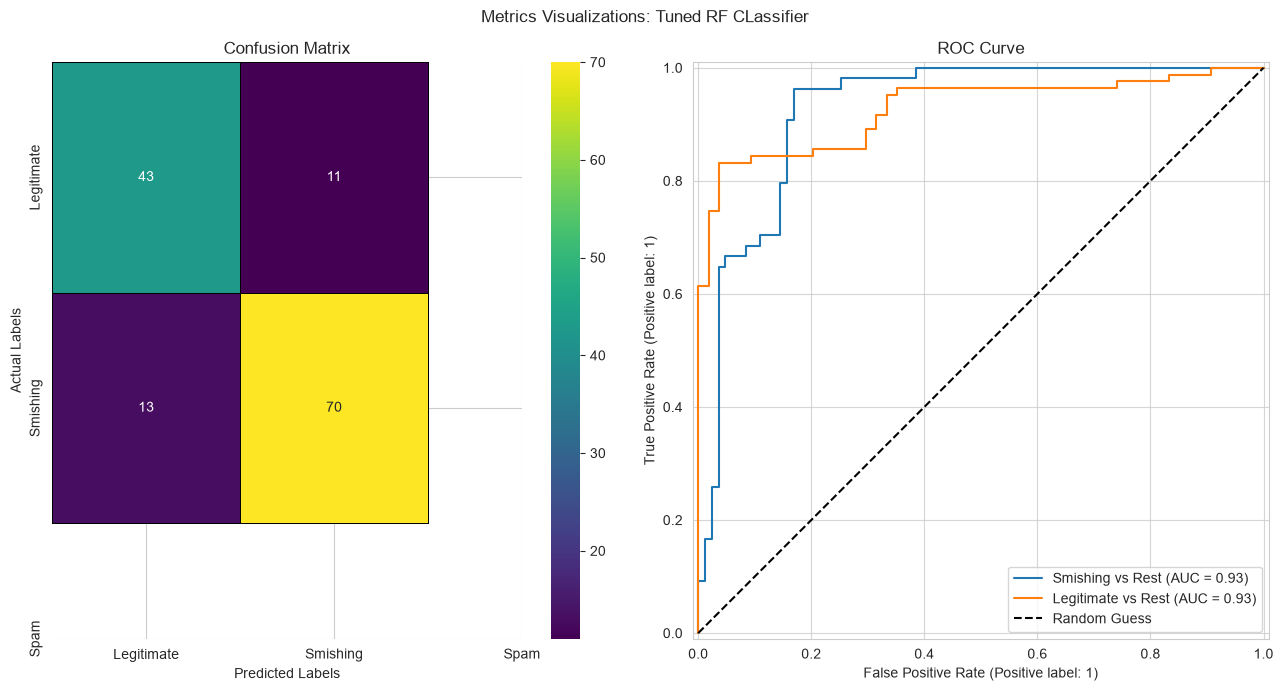

In [30]:
# 'rf__class_weight': None, 'rf__criterion': 'entropy', 
# 'rf__max_depth': 100, 'rf__max_features': 'log2', '
# rf__min_samples_leaf': 1, 'rf__min_samples_split': 4, 'rf__n_estimators': 200

rf = RandomForestClassifier(
    class_weight=None, criterion='entropy', max_depth=100,
    max_features='log2', min_samples_leaf=1, min_samples_split=4, n_estimators=200,
    random_state=42  
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, rf_pred)

show_metrics(y_test, rf_pred, rf_prob)
visualize_metrics(rf, cm, X_test, y_test, 'Tuned RF CLassifier', ['Smishing', 'Legitimate'])

In [31]:
# metrics without threshold tuning
show_metrics(y_test, ypred_cnb, yprob_cnb[:, 1])

Accuracy and ROC AUC Score
Accuracy Score: 70.803%
ROC AUC Score: 86.568%
              precision    recall  f1-score   support

           0       0.65      0.56      0.60        54
           1       0.74      0.81      0.77        83

    accuracy                           0.71       137
   macro avg       0.69      0.68      0.69       137
weighted avg       0.70      0.71      0.70       137



In [32]:
show_metrics(y_test, ypred_mnb, yprob_mnb[:, 1])

Accuracy and ROC AUC Score
Accuracy Score: 70.073%
ROC AUC Score: 85.788%
              precision    recall  f1-score   support

           0       0.64      0.56      0.59        54
           1       0.73      0.80      0.76        83

    accuracy                           0.70       137
   macro avg       0.69      0.68      0.68       137
weighted avg       0.70      0.70      0.70       137



## McNemar's Test on both MNB and CNB

MultinomialNB Accuracy: 70.07%
ComplementNB Accuracy: 70.80%
No significant difference between Model A and B Performance


Text(0.5, 1.0, "McNemar's Test Contingency Matrix")

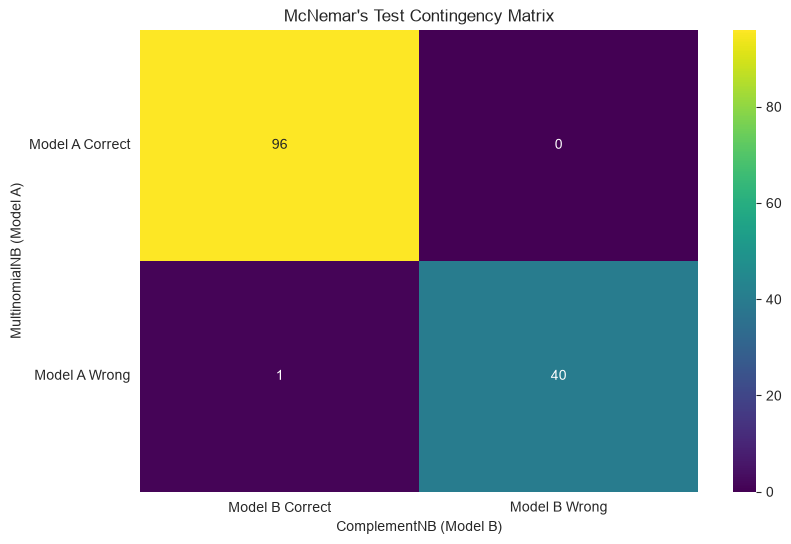

In [59]:
from statsmodels.stats.contingency_tables import mcnemar

y_true = y_test
y_model_a = mnb.predict(X_test)
y_model_b = cnb.predict(X_test)

correct_a = (y_model_a == y_true)
correct_b = (y_model_b == y_true)

contingency_tbl = pd.crosstab(correct_a, correct_b)

contingency_table = contingency_tbl.reindex(
    index=[True, False], columns=[True, False], fill_value=0
).to_numpy()

discordant_sum = contingency_table[0, 1] + contingency_table[1, 0]

if discordant_sum < 25:
    result = mcnemar(contingency_table, exact=True)
else: 
    result = mcnemar(contingency_table, exact=False, correction=True)

print(f"MultinomialNB Accuracy: {(accuracy_score(y_test, y_model_a) * 100):.2f}%")
print(f"ComplementNB Accuracy: {(accuracy_score(y_test, y_model_b) * 100):.2f}%")

alpha = 0.05
if result.pvalue < alpha:
    print("Statistically significant difference between Model A and B Performance")
else:
    print("No significant difference between Model A and B Performance")

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(contingency_table, annot=True, xticklabels=['Model B Correct', 'Model B Wrong'],
            yticklabels=['Model A Correct', 'Model A Wrong'], cmap='viridis')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va='center')
ax.set_xlabel("ComplementNB (Model B)")
ax.set_ylabel("MultinomialNB (Model A)")
ax.set_title("McNemar's Test Contingency Matrix")